# CSE475 — Task 2: Baselines
## TON_IoT (network) · Track 1: Graph Neural Network · Group 07, Section 01

**File:** `code/task2/Group07_TONIoT_task2_baselines.ipynb`

This notebook trains six standard classifiers on flow features, evaluates them with the
full metric set from the course brief (§6.1), and names the baseline our graph model must beat.

### Two evaluation protocols (from Task 1, §P4)

Task 1 showed each attack type in TON_IoT comes from a few specific attacking machines, so
a multiclass split by machine leaves 8 of 10 classes missing from at least one part.
We therefore use two protocols:

| Protocol | Task | Split | Why |
|---|---|---|---|
| **M** | 10-class | Stratified flow-level 70 / 15 / 15 | Every class in every part; comparable to published work |
| **B** | Binary (normal vs attack) | No source host shared between train / validation / test | Tests detection on machines never seen in training |

Rules: exact duplicates removed before splitting; identifiers (`src_ip`, `dst_ip`, ports) never
used as features; all preprocessing fitted on the training split only; model choice made on
validation macro-F1; test set used once.

## 0 · Setup and data

In [7]:
import os, json, time, pickle, warnings, random, ipaddress, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "figure.autolayout": True,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "axes.grid": True,
                     "grid.alpha": .25, "legend.frameon": False})
sns.set_palette("colorblind")
OUT = Path("figures"); OUT.mkdir(exist_ok=True)
def save(fig, name): fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
def reading(t): print("\nReading: " + t)

In [8]:
# ---- locate and load (same logic as Task 1) -------------------------------
def clean_cols(cols):
    return [str(c).replace("﻿", "").replace("ï»¿", "").strip().lower() for c in cols]

REQUIRED = {"src_ip", "dst_ip", "type"}
DATA_PATH = None
for root in ["/kaggle/input", ".", "data"]:
    if not os.path.isdir(root):
        continue
    for d, _, files in os.walk(root):
        for f in sorted(files):
            if f.lower().endswith(".csv"):
                p = Path(d) / f
                try:
                    if REQUIRED <= set(clean_cols(pd.read_csv(p, nrows=0, encoding="latin-1").columns)):
                        DATA_PATH = DATA_PATH or str(p)
                except Exception:
                    pass
assert DATA_PATH, "Attach the TON_IoT train_test_network.csv dataset via + Add Input."
print("Using:", DATA_PATH)

raw = pd.read_csv(DATA_PATH, encoding="latin-1", low_memory=False)
raw.columns = clean_cols(raw.columns)
df = raw.replace({"-": np.nan, "": np.nan})
df["type"] = df["type"].astype(str).str.strip().str.lower()
df["label"] = (df["type"] != "normal").astype(int)
for c in df.columns:
    if c in ("type", "src_ip", "dst_ip") or pd.api.types.is_numeric_dtype(df[c]):
        continue
    conv = pd.to_numeric(df[c], errors="coerce")
    if df[c].notna().any() and conv.notna().sum() >= 0.95 * df[c].notna().sum():
        df[c] = conv

n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)          # Task 1 §C: remove exact duplicates first
print(f"rows: {n0:,} -> {len(df):,} after removing {n0 - len(df):,} exact duplicates")

ID_COLS = [c for c in ["ts", "src_ip", "src_port", "dst_ip", "dst_port"] if c in df.columns]
TARGETS = ["label", "type"]
cand = [c for c in df.columns if c not in ID_COLS + TARGETS]
NUM = [c for c in cand if pd.api.types.is_numeric_dtype(df[c])]
OBJ = [c for c in cand if c not in NUM]
TEXT = [c for c in OBJ if df[c].nunique() > 100]           # free text, e.g. dns_query: not used
CAT = [c for c in OBJ if c not in TEXT]
CLASSES = sorted(df["type"].unique())
print(f"numeric {len(NUM)}, categorical {len(CAT)}, dropped free-text {TEXT}, identifiers {ID_COLS}")
print("classes:", CLASSES)

Using: /kaggle/input/datasets/afnanbd/train-test-network-csv/train_test_network.csv
rows: 211,043 -> 190,474 after removing 20,569 exact duplicates
numeric 17, categorical 20, dropped free-text ['dns_query'], identifiers ['src_ip', 'src_port', 'dst_ip', 'dst_port']
classes: ['backdoor', 'ddos', 'dos', 'injection', 'mitm', 'normal', 'password', 'ransomware', 'scanning', 'xss']


In [9]:
# ---- two evaluation protocols ---------------------------------------------
from sklearn.model_selection import train_test_split, StratifiedGroupKFold

# Protocol M (multiclass): stratified flow-level 70 / 15 / 15.
idx = np.arange(len(df))
m_tr, m_tmp = train_test_split(idx, test_size=0.30, stratify=df["type"], random_state=SEED)
m_va, m_te = train_test_split(m_tmp, test_size=0.50, stratify=df["type"].iloc[m_tmp], random_state=SEED)

# Protocol B (binary): no source host shared between train, validation and test.
groups = df["src_ip"].astype(str).values
yb = df["label"].values
def host_split(seed):
    folds = [te for _, te in StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=seed).split(idx, yb, groups)]
    te, va = folds[0], folds[1]
    return np.setdiff1d(idx, np.concatenate([te, va])), va, te
for s in range(50):
    b_tr, b_va, b_te = host_split(s)
    if all(len(np.unique(yb[p])) == 2 for p in (b_tr, b_va, b_te)):
        B_SEED = s; break
assert not (set(groups[b_tr]) & set(groups[b_te])) and not (set(groups[b_tr]) & set(groups[b_va]))

SPLIT = {"M": (m_tr, m_va, m_te), "B": (b_tr, b_va, b_te)}
for k, (a, b, c) in SPLIT.items():
    tgt = df["type"] if k == "M" else df["label"]
    print(f"Protocol {k}: train {len(a):,} | val {len(b):,} | test {len(c):,}"
          + (f" | source hosts {len(set(groups[a]))}/{len(set(groups[b]))}/{len(set(groups[c]))}" if k == "B" else ""))
    print("   test class counts:", tgt.iloc[c].value_counts().to_dict())
SPLIT_HASH = hashlib.md5(np.concatenate([m_te, b_te]).tobytes()).hexdigest()[:10]
print("split fingerprint (must match in both Task 2 notebooks):", SPLIT_HASH)

Protocol M: train 133,331 | val 28,571 | test 28,572
   test class counts: {'normal': 6306, 'scanning': 3000, 'ddos': 2999, 'injection': 2995, 'password': 2980, 'dos': 2849, 'backdoor': 2807, 'xss': 2270, 'ransomware': 2210, 'mitm': 156}
Protocol B: train 122,776 | val 41,432 | test 26,266 | source hosts 37/7/7
   test class counts: {0: 19883, 1: 6383}
split fingerprint (must match in both Task 2 notebooks): 70dd7b8009


## 1 · Preprocessing

| Step | Applied to | Why (Task 1 finding) |
|---|---|---|
| log1p | numeric | 16 of 17 numeric features have \|skew\| > 2 |
| median imputation + missing flag | numeric | Zeek `-` means "not applicable", which is information |
| standardisation | numeric | puts features on one scale for LR, SVM, MLP |
| constant "none" + one-hot (rare levels grouped) | categorical | `-` becomes its own category |
| class-balanced weights | all models | MITM is 48× smaller than Normal |

`dns_query` (free text) and identifier columns are not used.

In [10]:
# ---- preprocessing: fitted on the training split only ---------------------
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

def log1p_clip(X):
    return np.log1p(np.clip(X, 0, None))

def make_prep():
    num = Pipeline([("log", FunctionTransformer(log1p_clip)),
                    ("imp", SimpleImputer(strategy="median", add_indicator=True)),   # flags 'field not applicable'
                    ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="none")),
                    ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20,
                                         sparse_output=False))])
    return ColumnTransformer([("num", num, NUM), ("cat", cat, CAT)])

def prepare(protocol):
    tr, va, te = SPLIT[protocol]
    prep = make_prep().fit(df.iloc[tr][NUM + CAT].astype({c: str for c in CAT}))
    X = lambda ix: prep.transform(df.iloc[ix][NUM + CAT].astype({c: str for c in CAT})).astype(np.float32)
    return prep, X(tr), X(va), X(te)

In [11]:
# ---- metrics (course brief §6.1) ------------------------------------------
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, roc_curve, precision_recall_curve)
from sklearn.preprocessing import label_binarize

def evaluate(y_true, y_pred, scores, labels):
    """scores: (n, n_classes) probabilities or decision values, columns ordered as `labels`."""
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    out = {"accuracy": accuracy_score(y_true, y_pred), "macro_precision": p, "macro_recall": r,
           "macro_f1": f, "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0)}
    if len(labels) == 2:
        s = scores[:, 1] if scores.ndim == 2 else scores
        out["roc_auc"] = roc_auc_score(y_true, s); out["pr_auc"] = average_precision_score(y_true, s)
    else:
        Y = label_binarize(y_true, classes=labels)
        keep = Y.sum(0) > 0
        out["roc_auc"] = roc_auc_score(Y[:, keep], scores[:, keep], average="macro")      # one-vs-rest
        out["pr_auc"] = average_precision_score(Y[:, keep], scores[:, keep], average="macro")
    return out

def plot_curves(y_true, scores, labels, title, name):
    """One-vs-rest ROC and precision-recall curves."""
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    if len(labels) == 2:
        s = scores[:, 1] if scores.ndim == 2 else scores
        fpr, tpr, _ = roc_curve(y_true, s); pr, rc, _ = precision_recall_curve(y_true, s)
        ax[0].plot(fpr, tpr, label=f"AUC {roc_auc_score(y_true, s):.3f}")
        ax[1].plot(rc, pr, label=f"AP {average_precision_score(y_true, s):.3f}")
    else:
        Y = label_binarize(y_true, classes=list(range(len(labels))))   # y_true is integer-coded
        for i, c in enumerate(labels):
            if Y[:, i].sum() == 0: continue
            fpr, tpr, _ = roc_curve(Y[:, i], scores[:, i]); pr, rc, _ = precision_recall_curve(Y[:, i], scores[:, i])
            ax[0].plot(fpr, tpr, lw=1.2, label=f"{c} ({roc_auc_score(Y[:, i], scores[:, i]):.3f})")
            ax[1].plot(rc, pr, lw=1.2, label=f"{c} ({average_precision_score(Y[:, i], scores[:, i]):.3f})")
    ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
    ax[0].set(title="ROC (one-vs-rest)", xlabel="False positive rate", ylabel="True positive rate")
    ax[1].set(title="Precision-recall (one-vs-rest)", xlabel="Recall", ylabel="Precision")
    for a in ax: a.legend(fontsize=7)
    fig.suptitle(title, fontweight="bold"); save(fig, name); plt.show()

def plot_cm(y_true, y_pred, labels, title, name, ax=None):
    cm = confusion_matrix(y_true, y_pred, labels=labels, normalize="true")
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(7.5, 6))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels,
                ax=ax, cbar=False, annot_kws={"size": 7}, vmin=0, vmax=1)
    ax.set(title=title, xlabel="Predicted", ylabel="True")
    if own: save(fig, name); plt.show()

In [12]:
prep_M, Xtr, Xva, Xte = prepare("M")
tr, va, te = SPLIT["M"]
ytr, yva, yte = (df["type"].iloc[i].values for i in (tr, va, te))
print("feature matrix:", Xtr.shape, "| classes:", len(CLASSES))

feature matrix: (133331, 99) | classes: 10


## 2 · Baseline models

| Model | Why it is here |
|---|---|
| Logistic Regression | simplest linear reference |
| Linear SVM | linear, margin-based |
| Decision Tree | interpretable, non-linear |
| Random Forest | strong ensemble of trees |
| XGBoost | usually the strongest model on tabular data |
| MLP | a neural network without graph structure — the fairest comparison for a GNN |

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

def make_models(n_classes):
    return {
        "Logistic Regression": LogisticRegression(max_iter=400, class_weight="balanced", n_jobs=-1),
        "Linear SVM": LinearSVC(class_weight="balanced", C=0.5, max_iter=3000),
        "Decision Tree": DecisionTreeClassifier(class_weight="balanced", min_samples_leaf=2, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=SEED),
        "XGBoost": XGBClassifier(n_estimators=400, max_depth=8, learning_rate=0.1, tree_method="hist",
                                 subsample=0.9, colsample_bytree=0.8, n_jobs=-1, random_state=SEED,
                                 eval_metric="mlogloss" if n_classes > 2 else "logloss",
                                 early_stopping_rounds=30),
        "MLP": MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=60,
                             random_state=SEED),
    }

def scores_of(m, X):
    return m.predict_proba(X) if hasattr(m, "predict_proba") else m.decision_function(X)

def run_all(Xtr, ytr, Xva, yva, Xte, yte, labels, tag):
    enc = {c: i for i, c in enumerate(labels)}
    ytr_i, yva_i, yte_i = (np.array([enc[v] for v in y]) for y in (ytr, yva, yte))
    rows, fitted, preds = [], {}, {}
    for name, m in make_models(len(labels)).items():
        t0 = time.time()
        if name == "XGBoost":
            m.fit(Xtr, ytr_i, sample_weight=compute_sample_weight("balanced", ytr_i),
                  eval_set=[(Xva, yva_i)], verbose=False)
        elif name == "MLP":
            m.fit(Xtr, ytr_i)
        else:
            m.fit(Xtr, ytr_i)
        t_train = time.time() - t0
        t0 = time.time(); p_te = m.predict(Xte); s_te = scores_of(m, Xte); t_inf = time.time() - t0
        val_f1 = f1_score(yva_i, m.predict(Xva), average="macro")
        r = evaluate(yte_i, p_te, s_te, list(range(len(labels))))
        r.update(model=name, val_macro_f1=val_f1, train_s=t_train,
                 infer_ms_per_1k=t_inf / len(Xte) * 1e6,   # milliseconds per 1,000 flows
                 size_MB=len(pickle.dumps(m)) / 1e6)
        rows.append(r); fitted[name] = m; preds[name] = (p_te, s_te)
        print(f"{name:<20} val macro-F1 {val_f1:.4f} | test macro-F1 {r['macro_f1']:.4f} | {t_train:6.1f}s")
    res = pd.DataFrame(rows).set_index("model")
    cols = ["val_macro_f1", "accuracy", "macro_precision", "macro_recall", "macro_f1", "weighted_f1",
            "roc_auc", "pr_auc", "train_s", "infer_ms_per_1k", "size_MB"]
    res = res[cols].sort_values("val_macro_f1", ascending=False)
    res.round(4).to_csv(f"baselines_{tag}.csv")
    return res, fitted, preds, yte_i

## 3 · Protocol M — 10-class, flow-level split

In [14]:
resM, fitM, predM, yteM = run_all(Xtr, ytr, Xva, yva, Xte, yte, CLASSES, "M")
resM.round(4)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression  val macro-F1 0.8635 | test macro-F1 0.8642 |   48.1s
Linear SVM           val macro-F1 0.8189 | test macro-F1 0.8179 |  218.5s
Decision Tree        val macro-F1 0.9469 | test macro-F1 0.9467 |    1.1s
Random Forest        val macro-F1 0.9551 | test macro-F1 0.9501 |   15.9s
XGBoost              val macro-F1 0.9553 | test macro-F1 0.9509 |   72.7s
MLP                  val macro-F1 0.9447 | test macro-F1 0.9357 |  123.4s


,val_macro_f1,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc,pr_auc,train_s,infer_ms_per_1k,size_MB
model,,,,,,,,,,,
XGBoost,0.9553,0.9790,0.9404,0.9665,0.9509,0.9794,0.9994,0.9785,72.6620,65.2816,8.6151
Random Forest,0.9551,0.9771,0.9470,0.9537,0.9501,0.9771,0.9969,0.9696,15.9380,23.9700,126.1299
Decision Tree,0.9469,0.9756,0.9416,0.9528,0.9467,0.9758,0.9830,0.9428,1.1167,0.4793,0.5515
MLP,0.9447,0.9715,0.9348,0.9371,0.9357,0.9717,0.9987,0.9647,123.3755,13.3392,0.2696
Logistic Regression,0.8635,0.9222,0.8627,0.9136,0.8642,0.9271,0.9909,0.9026,48.0663,1.3460,0.0088
Linear SVM,0.8189,0.8780,0.8192,0.8582,0.8179,0.8815,0.9777,0.8255,218.5450,0.7222,0.0087


Baseline to beat (highest validation macro-F1): XGBoost
              precision    recall  f1-score   support

    backdoor     1.0000    0.9996    0.9998      2807
        ddos     0.9892    0.9780    0.9836      2999
         dos     0.9904    0.9810    0.9857      2849
   injection     0.9891    0.9659    0.9774      2995
        mitm     0.6089    0.8782    0.7192       156
      normal     0.9979    0.9943    0.9961      6306
    password     0.9973    0.9779    0.9875      2980
  ransomware     0.9153    0.9729    0.9432      2210
    scanning     0.9864    0.9917    0.9890      3000
         xss     0.9296    0.9251    0.9274      2270

    accuracy                         0.9790     28572
   macro avg     0.9404    0.9665    0.9509     28572
weighted avg     0.9803    0.9790    0.9794     28572



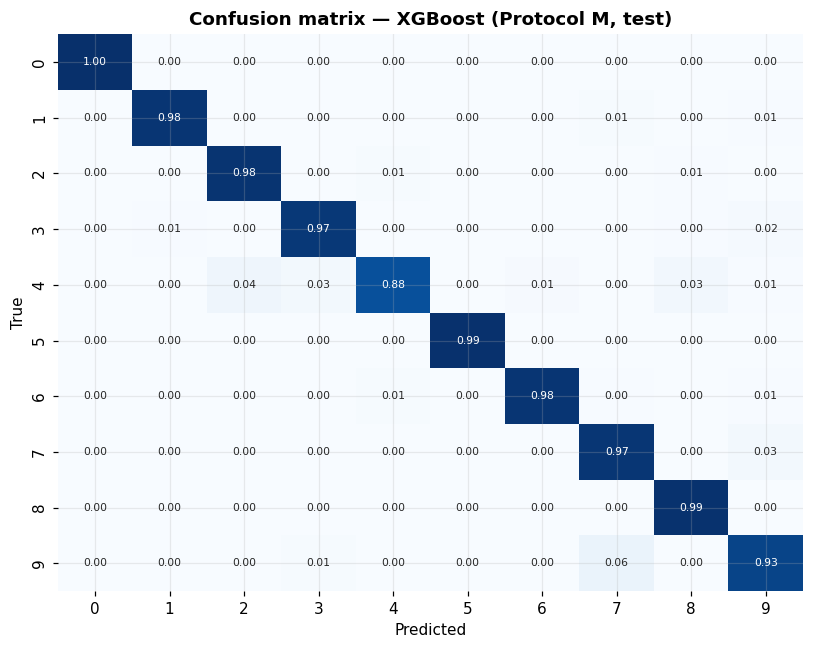

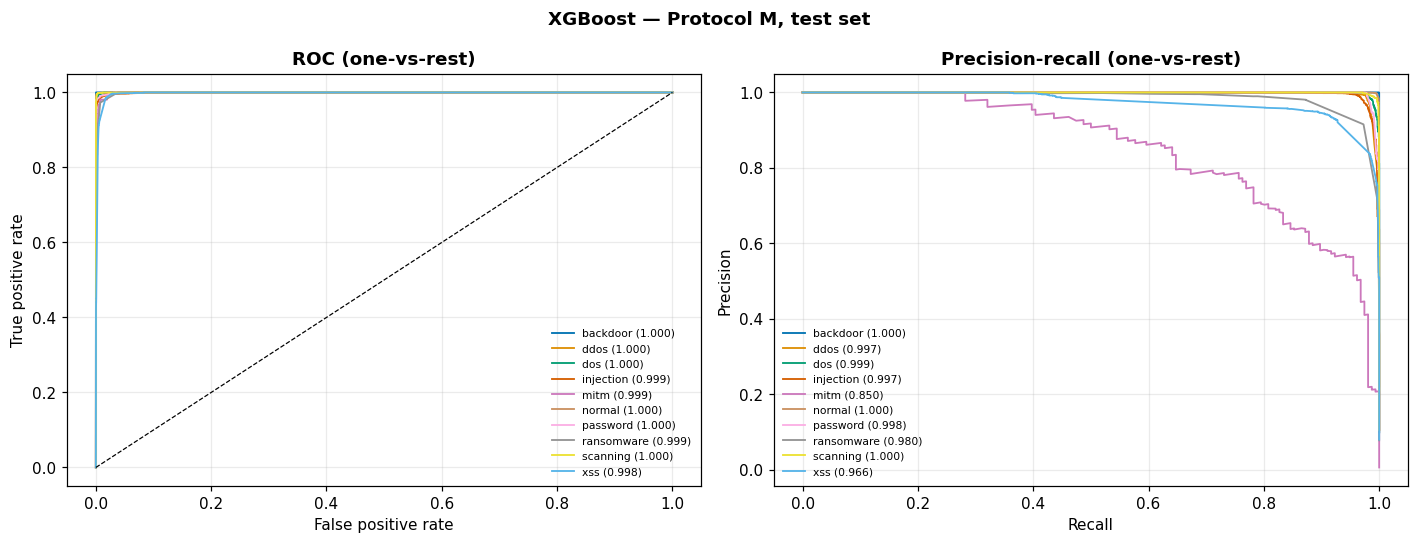


Reading: XGBoost reaches test macro-F1 0.9509. Off-diagonal cells in the confusion matrix show which attack types are confused.


In [15]:
BEST_M = resM.index[0]
print(f"Baseline to beat (highest validation macro-F1): {BEST_M}")
p, s = predM[BEST_M]
print(classification_report(yteM, p, target_names=CLASSES, digits=4, zero_division=0))
plot_cm(yteM, p, list(range(len(CLASSES))), f"Confusion matrix — {BEST_M} (Protocol M, test)", "M_cm_best")
plot_curves(yteM, s, CLASSES, f"{BEST_M} — Protocol M, test set", "M_curves_best")
reading(f"{BEST_M} reaches test macro-F1 {resM.loc[BEST_M, 'macro_f1']:.4f}. Off-diagonal cells in "
        "the confusion matrix show which attack types are confused.")

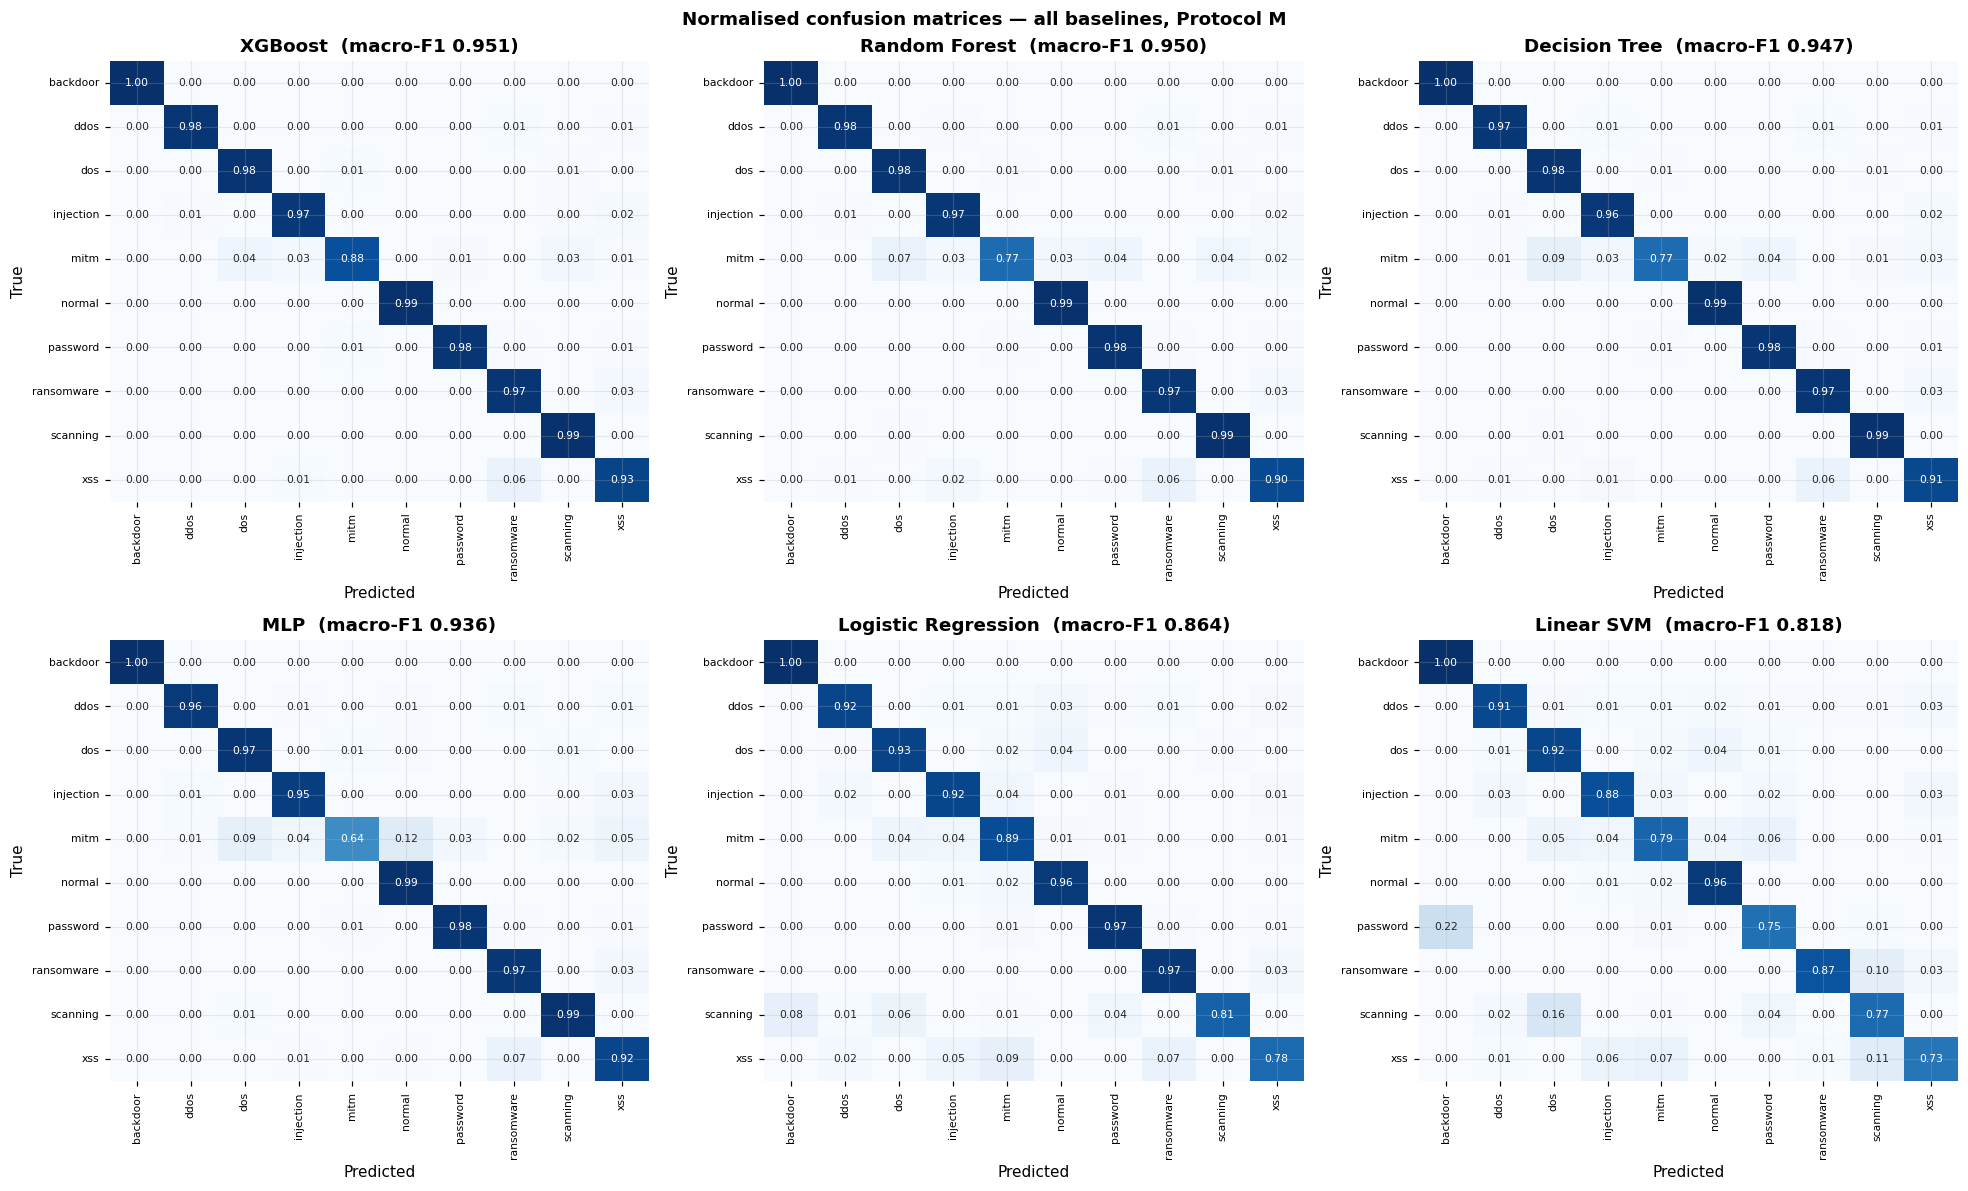

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, name in zip(axes.ravel(), resM.index):
    plot_cm(yteM, predM[name][0], list(range(len(CLASSES))), f"{name}  (macro-F1 {resM.loc[name,'macro_f1']:.3f})", None, ax=ax)
    ax.set_xticklabels(CLASSES, rotation=90, fontsize=7); ax.set_yticklabels(CLASSES, rotation=0, fontsize=7)
fig.suptitle("Normalised confusion matrices — all baselines, Protocol M", fontweight="bold")
save(fig, "M_cm_all"); plt.show()

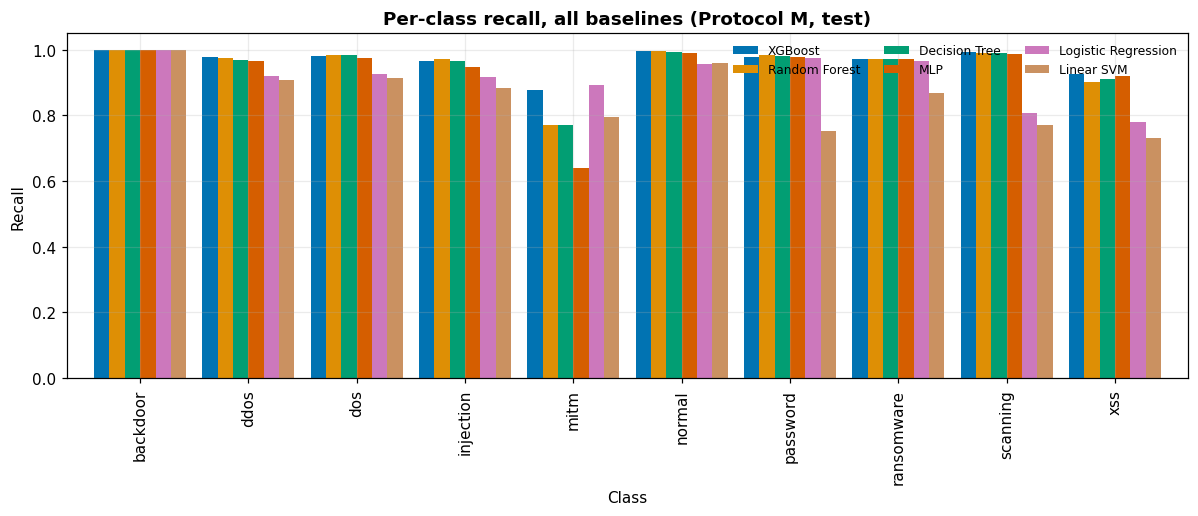


Reading: Classes with low recall across every model are hard on flow features alone — the cases where host context might help.


,XGBoost,Random Forest,Decision Tree,MLP,Logistic Regression,Linear SVM
backdoor,1.000,1.000,0.999,1.000,0.998,0.999
ddos,0.978,0.976,0.969,0.965,0.920,0.909
dos,0.981,0.984,0.984,0.973,0.926,0.915
injection,0.966,0.970,0.965,0.946,0.917,0.884
mitm,0.878,0.769,0.769,0.641,0.891,0.795
normal,0.994,0.994,0.992,0.991,0.957,0.960
password,0.978,0.982,0.979,0.977,0.974,0.751
ransomware,0.973,0.972,0.973,0.971,0.966,0.867
scanning,0.992,0.989,0.988,0.987,0.808,0.770
xss,0.925,0.900,0.910,0.921,0.779,0.732


In [17]:
per_class = pd.DataFrame({n: precision_recall_fscore_support(yteM, predM[n][0], labels=range(len(CLASSES)),
                                                             zero_division=0)[1] for n in resM.index},
                         index=CLASSES)
per_class.round(3).to_csv("baselines_M_per_class_recall.csv")
fig, ax = plt.subplots(figsize=(11, 4.8))
per_class.plot(kind="bar", ax=ax, width=.85)
ax.set(title="Per-class recall, all baselines (Protocol M, test)", xlabel="Class", ylabel="Recall", ylim=(0, 1.05))
ax.legend(fontsize=8, ncol=3); save(fig, "M_per_class_recall"); plt.show()
reading("Classes with low recall across every model are hard on flow features alone — the cases "
        "where host context might help.")
per_class.round(3)

## 4 · Protocol B — binary, unseen source hosts

In [18]:
prep_B, XtrB, XvaB, XteB = prepare("B")
trB, vaB, teB = SPLIT["B"]
yB = df["label"].map({0: "normal", 1: "attack"})
resB, fitB, predB, yteB = run_all(XtrB, yB.iloc[trB].values, XvaB, yB.iloc[vaB].values,
                                  XteB, yB.iloc[teB].values, ["normal", "attack"], "B")
resB.round(4)

Logistic Regression  val macro-F1 0.9387 | test macro-F1 0.9757 |    5.4s
Linear SVM           val macro-F1 0.9499 | test macro-F1 0.9816 |    4.1s
Decision Tree        val macro-F1 0.8138 | test macro-F1 0.8579 |    1.2s
Random Forest        val macro-F1 0.8626 | test macro-F1 0.8791 |   11.8s
XGBoost              val macro-F1 0.9858 | test macro-F1 0.9872 |    2.6s
MLP                  val macro-F1 0.8420 | test macro-F1 0.8731 |   48.8s


,val_macro_f1,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,roc_auc,pr_auc,train_s,infer_ms_per_1k,size_MB
model,,,,,,,,,,,
XGBoost,0.9858,0.9904,0.9820,0.9926,0.9872,0.9905,0.9957,0.9849,2.5544,1.8971,0.4067
Linear SVM,0.9499,0.9864,0.9799,0.9834,0.9816,0.9865,0.9943,0.9726,4.0768,0.4438,0.0014
Logistic Regression,0.9387,0.9821,0.9768,0.9746,0.9757,0.9821,0.9947,0.9743,5.3617,0.6610,0.0015
Random Forest,0.8626,0.8999,0.8541,0.9328,0.8791,0.9049,0.9969,0.9940,11.8334,11.1065,16.2724
MLP,0.8420,0.8944,0.8484,0.9292,0.8731,0.8998,0.9616,0.8925,48.8403,8.2958,0.2524
Decision Tree,0.8138,0.8802,0.8346,0.9196,0.8579,0.8869,0.8910,0.5871,1.2397,0.2411,0.0670


Best on Protocol B: XGBoost
              precision    recall  f1-score   support

      normal     0.9990    0.9884    0.9937     19883
      attack     0.9650    0.9969    0.9807      6383

    accuracy                         0.9904     26266
   macro avg     0.9820    0.9926    0.9872     26266
weighted avg     0.9907    0.9904    0.9905     26266



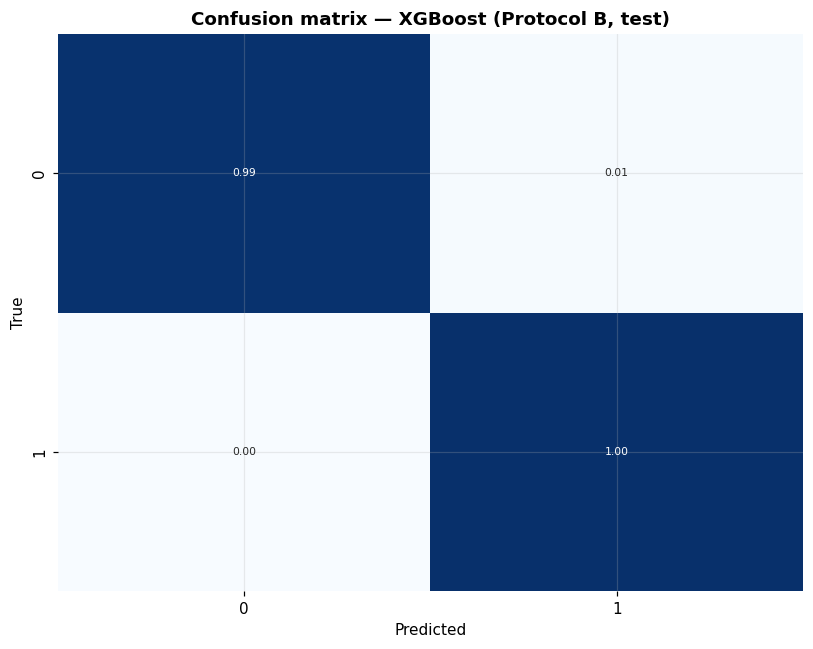

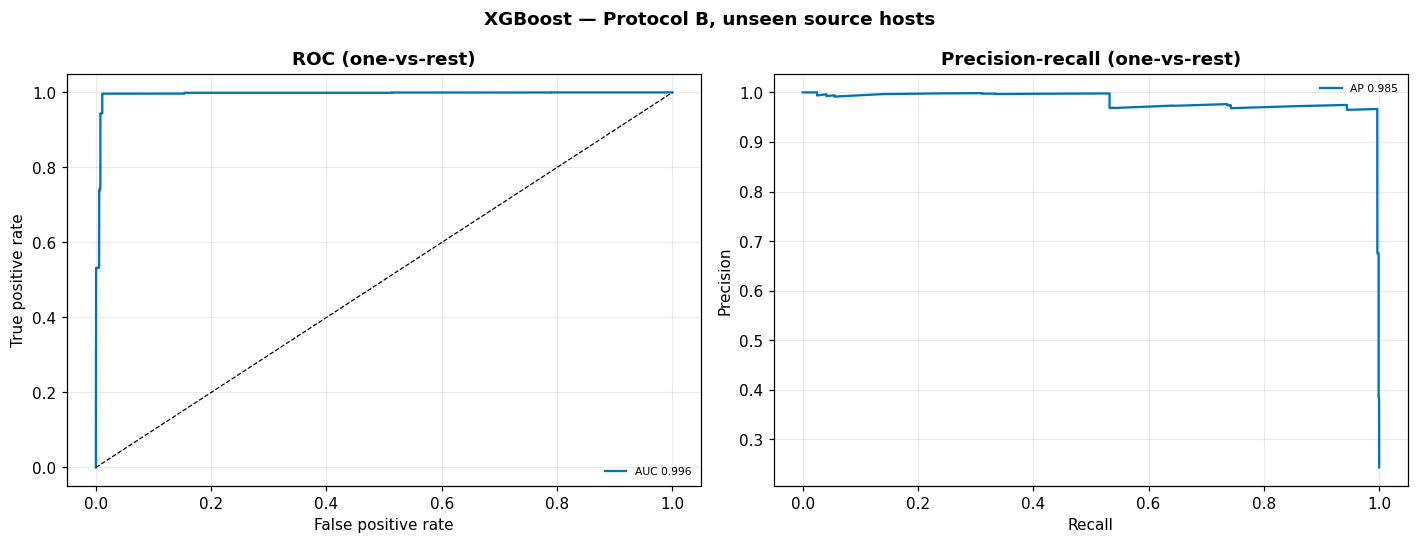

In [19]:
BEST_B = resB.index[0]
p, s = predB[BEST_B]
print(f"Best on Protocol B: {BEST_B}")
print(classification_report(yteB, p, target_names=["normal", "attack"], digits=4, zero_division=0))
plot_cm(yteB, p, [0, 1], f"Confusion matrix — {BEST_B} (Protocol B, test)", "B_cm_best")
plot_curves(yteB, s, ["normal", "attack"], f"{BEST_B} — Protocol B, unseen source hosts", "B_curves_best")

## 5 · Label-quality check (Task 1, §P3)

Task 1 found most flows touching the gateway `192.168.1.1`, and most flows leaving the private
network, are labelled as attacks — possible labelling artefacts (Raskovalov et al., 2022).
We retrain the best Protocol M model without those flows to see how much they matter.

In [20]:
def is_private(ip):
    try: return ipaddress.ip_address(str(ip)).is_private
    except ValueError: return False
suspect = ((df["src_ip"] == "192.168.1.1") | (df["dst_ip"] == "192.168.1.1") | ~df["dst_ip"].map(is_private)).values
keep = lambda ix: ix[~suspect[ix]]
tr2, va2, te2 = (keep(i) for i in SPLIT["M"])
print(f"suspect flows: {suspect.sum():,} ({suspect.mean()*100:.1f}%)")

prep2 = make_prep().fit(df.iloc[tr2][NUM + CAT].astype({c: str for c in CAT}))
T = lambda ix: prep2.transform(df.iloc[ix][NUM + CAT].astype({c: str for c in CAT})).astype(np.float32)
enc = {c: i for i, c in enumerate(CLASSES)}
m2 = make_models(len(CLASSES))[BEST_M]
y2 = lambda ix: np.array([enc[v] for v in df["type"].iloc[ix]])
if BEST_M == "XGBoost":
    m2.fit(T(tr2), y2(tr2), sample_weight=compute_sample_weight("balanced", y2(tr2)), eval_set=[(T(va2), y2(va2))], verbose=False)
else:
    m2.fit(T(tr2), y2(tr2))
f_without = f1_score(y2(te2), m2.predict(T(te2)), average="macro")
print(f"{BEST_M} macro-F1 with all flows   : {resM.loc[BEST_M, 'macro_f1']:.4f}")
print(f"{BEST_M} macro-F1 without suspects : {f_without:.4f}")
LABEL_CHECK = {"suspect_flows": int(suspect.sum()), "with": float(resM.loc[BEST_M, "macro_f1"]), "without": float(f_without)}
reading("A small difference means the suspect labels do not drive the results; a large one means "
        "headline numbers partly reflect labelling artefacts.")

suspect flows: 37,145 (19.5%)
XGBoost macro-F1 with all flows   : 0.9509
XGBoost macro-F1 without suspects : 0.9680

Reading: A small difference means the suspect labels do not drive the results; a large one means headline numbers partly reflect labelling artefacts.


## 6 · Summary

In [21]:
summary = {"split_fingerprint": SPLIT_HASH, "rows_after_dedup": int(len(df)),
           "protocol_M": resM.round(4).reset_index().to_dict("records"), "best_M": BEST_M,
           "protocol_B": resB.round(4).reset_index().to_dict("records"), "best_B": BEST_B,
           "label_check": LABEL_CHECK,
           "per_class_recall_M": per_class.round(4).to_dict()}
Path("baselines_results.json").write_text(json.dumps(summary, indent=2, default=float))
print(f"Baseline to beat — Protocol M: {BEST_M} (test macro-F1 {resM.loc[BEST_M,'macro_f1']:.4f})")
print(f"Baseline to beat — Protocol B: {BEST_B} (test macro-F1 {resB.loc[BEST_B,'macro_f1']:.4f})")
print("Saved baselines_results.json, baselines_M.csv, baselines_B.csv and figures/.")

Baseline to beat — Protocol M: XGBoost (test macro-F1 0.9509)
Baseline to beat — Protocol B: XGBoost (test macro-F1 0.9872)
Saved baselines_results.json, baselines_M.csv, baselines_B.csv and figures/.
